In [33]:
# import libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [34]:
# read data
df = pd.read_csv("../../../data/merged/score_100/tmdb_numbers_100.csv")

In [35]:
df.columns

Index(['tmdb_index', 'numbers_index', 'tmdb_title', 'tmdb_normalized',
       'tmdb_year', 'numbers_title', 'numbers_normalized', 'numbers_year',
       'similarity', 'tmdb_id', 'title', 'original_title', 'release_date',
       'year', 'genre_ids', 'popularity', 'vote_average', 'vote_count',
       'original_language', 'adult', 'rank', 'title_numbers', 'year_numbers',
       'domestic_box_office', 'international_box_office',
       'worldwide_box_office', 'domestic_share', 'url'],
      dtype='str')

In [36]:
columns_to_remove = [
    'tmdb_index',
    'numbers_index',
    'tmdb_title',
    'tmdb_normalized',
    'tmdb_year',
    'numbers_title',
    'numbers_normalized',
    'numbers_year',
    'title_numbers',
    'year_numbers',
    'tmdb_id',
    'similarity',
    'original_title',
    'url'
]

df = df.drop(
    columns=columns_to_remove
)

In [37]:
df.columns

Index(['title', 'release_date', 'year', 'genre_ids', 'popularity',
       'vote_average', 'vote_count', 'original_language', 'adult', 'rank',
       'domestic_box_office', 'international_box_office',
       'worldwide_box_office', 'domestic_share'],
      dtype='str')

In [38]:
df.head(5)

,title,release_date,year,genre_ids,popularity,vote_average,vote_count,original_language,adult,rank,domestic_box_office,international_box_office,worldwide_box_office,domestic_share
0,Alita: Battle Angel,2019-01-31,2019,"[28, 878, 12]",19.5410,7.278,10405,en,False,20,85838210.0,316061830.0,401900040.0,21.4
1,1917,2019-12-25,2019,"[10752, 18, 36]",19.0714,7.983,13929,en,False,22,159227644.0,224482428.0,383710072.0,41.5
2,1921,2021-07-01,2021,"[36, 18, 10752]",2.2643,5.500,17,zh,False,56,0.0,75017096.0,75017096.0,0.0
3,Shelter,2026-03-06,2026,[99],1.8203,6.000,1,es,False,53,12805541.0,36500000.0,49305541.0,26.0
4,Obsession,2026-09-14,2026,[18],1.8521,0.000,0,ru,False,10,263451715.0,253280000.0,516731715.0,51.0


In [39]:
df['original_language'].unique()

<StringArray>
['en', 'zh', 'es', 'ru', 'ja', 'hi', 'te', 'ko', 'ta', 'kn', 'pt', 'tr', 'fr',
 'uk', 'cn', 'ml', 'it', 'pl', 'tl', 'el', 'de', 'fa', 'sv', 'uz']
Length: 24, dtype: str

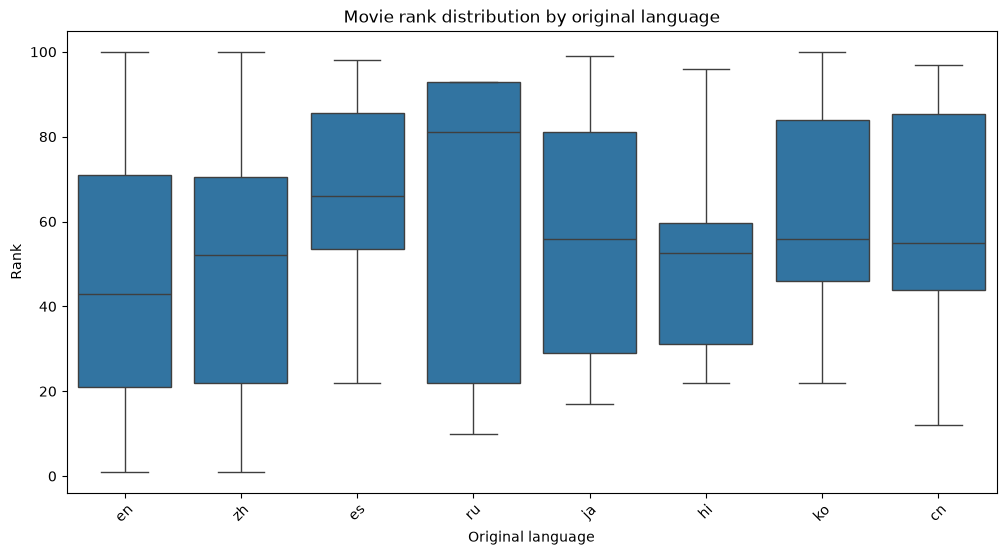

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

languages = (
    df['original_language']
    .value_counts()
    .loc[lambda x: x >= 5]
    .index
)

df_plot = df[df['original_language'].isin(languages)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_plot, x='original_language', y='rank')

plt.xlabel('Original language')
plt.ylabel('Rank')
plt.title('Movie rank distribution by original language')
plt.xticks(rotation=45)
plt.show()